# 1. Installation et importation des librairies

In [110]:
import kagglehub
import pandas as pd
import numpy as np
import sqlite3
import time
import joblib
from pathlib import Path

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

# 2. Création des dossiers du projet

In [111]:
DATA_DIR = Path("data")
OUTPUT_DIR = Path("outputs")
MODEL_DIR = Path("models")
FIGURE_DIR = Path("figures")

DATA_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(exist_ok=True)

# 3. Téléchargement du dataset Kaggle

In [112]:
path = kagglehub.dataset_download("kanchana1990/ev-battery-qc-synthetic-defect-dataset")

print("Chemin du dataset :", path)

Chemin du dataset : /Users/ouissalmasbahi/.cache/kagglehub/datasets/kanchana1990/ev-battery-qc-synthetic-defect-dataset/versions/1


# 4. Chargement automatique du fichier CSV

In [113]:
dataset_path = Path(path)

csv_files = list(dataset_path.glob("*.csv"))

print("Fichiers CSV trouvés :")
for file in csv_files:
    print("-", file.name)

if len(csv_files) == 0:
    raise FileNotFoundError("Aucun fichier CSV trouvé dans le dossier téléchargé.")

csv_path = csv_files[0]
print("Fichier utilisé :", csv_path)

df = pd.read_csv(csv_path)

print("Dimensions du dataset :", df.shape)
df.head()

Fichiers CSV trouvés :
- ev_battery_qc_data_2026_kaggle.csv
Fichier utilisé : /Users/ouissalmasbahi/.cache/kagglehub/datasets/kanchana1990/ev-battery-qc-synthetic-defect-dataset/versions/1/ev_battery_qc_data_2026_kaggle.csv
Dimensions du dataset : (20000, 14)


,Cell_ID,Batch_ID,Production_Line,Shift,Supplier,Ambient_Temp_C,Anode_Overhang_mm,Electrolyte_Volume_ml,Internal_Resistance_mOhm,Capacity_mAh,Retention_50Cycle_Pct,Defect_Type,Inspector_Comment,QC_Grade
0,CELL-004920,BTH-0001,Line_3,Evening,ChemCorp,20.76,0.108,14.81,14.01,4980.0,97.79,Poor Retention,NaN,Scrap
1,CELL-014782,BTH-0001,Line_1,Night,ChemCorp,22.38,0.126,14.96,14.70,4989.0,97.35,NaN,NaN,Grade A
2,CELL-019348,BTH-0001,Line_2,Night,LithioMat,20.18,0.135,14.97,13.80,5032.0,96.77,NaN,Routine visual inspection passed.,Grade A
3,CELL-008537,BTH-0001,Line_2,Morning,VoltIndustries,24.30,0.162,14.84,14.65,5042.0,95.88,NaN,NaN,Grade A
4,CELL-010539,BTH-0001,Line_1,Evening,VoltIndustries,22.22,0.130,14.89,15.04,4943.0,97.74,High Internal Resistance,NaN,Grade A


# 5. Première exploration des données

In [62]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Cell_ID                   20000 non-null  object 
 1   Batch_ID                  20000 non-null  object 
 2   Production_Line           20000 non-null  object 
 3   Shift                     20000 non-null  object 
 4   Supplier                  20000 non-null  object 
 5   Ambient_Temp_C            19400 non-null  float64
 6   Anode_Overhang_mm         20000 non-null  float64
 7   Electrolyte_Volume_ml     20000 non-null  float64
 8   Internal_Resistance_mOhm  20000 non-null  float64
 9   Capacity_mAh              20000 non-null  float64
 10  Retention_50Cycle_Pct     20000 non-null  float64
 11  Defect_Type               3501 non-null   object 
 12  Inspector_Comment         1667 non-null   object 
 13  QC_Grade                  20000 non-null  object 
dtypes: flo

In [63]:
df.describe(include="all")

,Cell_ID,Batch_ID,Production_Line,Shift,Supplier,Ambient_Temp_C,Anode_Overhang_mm,Electrolyte_Volume_ml,Internal_Resistance_mOhm,Capacity_mAh,Retention_50Cycle_Pct,Defect_Type,Inspector_Comment,QC_Grade
count,20000,20000,20000,20000,20000,19400.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,3501,1667,20000
unique,20000,499,3,3,3,NaN,NaN,NaN,NaN,NaN,NaN,6,7,3
top,CELL-004920,BTH-0273,Line_1,Evening,ChemCorp,NaN,NaN,NaN,NaN,NaN,NaN,High Internal Resistance,Standard calibration OK.,Grade A
freq,1,63,8038,6768,9908,NaN,NaN,NaN,NaN,NaN,NaN,2837,311,13193
mean,NaN,NaN,NaN,NaN,NaN,23.157409,0.137498,14.979050,14.280926,4988.398450,96.801533,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,1.890930,0.020991,0.119464,0.705987,48.205605,1.170866,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,16.260000,0.057000,14.430000,11.900000,4576.000000,90.210000,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,21.860000,0.123000,14.910000,13.790000,4971.000000,96.350000,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,23.250000,0.138000,14.990000,14.200000,4995.000000,96.940000,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,24.490000,0.152000,15.060000,14.680000,5017.000000,97.510000,NaN,NaN,NaN


In [64]:
print("Nombre de lignes :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])

print("\nListe des colonnes :")
for col in df.columns:
    print("-", col)

Nombre de lignes : 20000
Nombre de colonnes : 14

Liste des colonnes :
- Cell_ID
- Batch_ID
- Production_Line
- Shift
- Supplier
- Ambient_Temp_C
- Anode_Overhang_mm
- Electrolyte_Volume_ml
- Internal_Resistance_mOhm
- Capacity_mAh
- Retention_50Cycle_Pct
- Defect_Type
- Inspector_Comment
- QC_Grade


# 6. Création de la base de données SQLite

In [65]:
DB_PATH = OUTPUT_DIR / "battery_qc.sqlite"

conn = sqlite3.connect(DB_PATH)

df.to_sql("battery_qc_raw", conn, if_exists="replace", index=False)

print("Base SQLite créée :", DB_PATH)

Base SQLite créée : outputs/battery_qc.sqlite


# 7. Affichage des tables par défaut

In [66]:
tables = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table';",
    conn
)

tables

,name
0,battery_qc_clean
1,battery_qc_raw


In [67]:
raw_preview = pd.read_sql_query(
    "SELECT * FROM battery_qc_raw LIMIT 5;",
    conn
)

raw_preview

,Cell_ID,Batch_ID,Production_Line,Shift,Supplier,Ambient_Temp_C,Anode_Overhang_mm,Electrolyte_Volume_ml,Internal_Resistance_mOhm,Capacity_mAh,Retention_50Cycle_Pct,Defect_Type,Inspector_Comment,QC_Grade
0,CELL-004920,BTH-0001,Line_3,Evening,ChemCorp,20.76,0.108,14.81,14.01,4980.0,97.79,Poor Retention,None,Scrap
1,CELL-014782,BTH-0001,Line_1,Night,ChemCorp,22.38,0.126,14.96,14.70,4989.0,97.35,None,None,Grade A
2,CELL-019348,BTH-0001,Line_2,Night,LithioMat,20.18,0.135,14.97,13.80,5032.0,96.77,None,Routine visual inspection passed.,Grade A
3,CELL-008537,BTH-0001,Line_2,Morning,VoltIndustries,24.30,0.162,14.84,14.65,5042.0,95.88,None,None,Grade A
4,CELL-010539,BTH-0001,Line_1,Evening,VoltIndustries,22.22,0.130,14.89,15.04,4943.0,97.74,High Internal Resistance,None,Grade A


# 8. Analyse des valeurs manquantes

In [68]:
missing_values = df.isna().sum().sort_values(ascending=False)
missing_percent = (df.isna().mean() * 100).sort_values(ascending=False)

missing_report = pd.DataFrame({
    "valeurs_manquantes": missing_values,
    "pourcentage": missing_percent
})

missing_report

,valeurs_manquantes,pourcentage
Inspector_Comment,18333,91.665
Defect_Type,16499,82.495
Ambient_Temp_C,600,3.000
Cell_ID,0,0.000
Batch_ID,0,0.000
Production_Line,0,0.000
Shift,0,0.000
Supplier,0,0.000
Anode_Overhang_mm,0,0.000
Electrolyte_Volume_ml,0,0.000


In [69]:
missing_report[missing_report["valeurs_manquantes"] > 0]

,valeurs_manquantes,pourcentage
Inspector_Comment,18333,91.665
Defect_Type,16499,82.495
Ambient_Temp_C,600,3.000


# 9. Analyse des doublons

In [70]:
duplicates_count = df.duplicated().sum()

print("Nombre de doublons détectés :", duplicates_count)

Nombre de doublons détectés : 0


# 10. Vérification des types de données

In [71]:
types_report = pd.DataFrame({
    "colonne": df.columns,
    "type": df.dtypes.astype(str),
    "valeurs_uniques": [df[col].nunique() for col in df.columns]
})

types_report

,colonne,type,valeurs_uniques
Cell_ID,Cell_ID,object,20000
Batch_ID,Batch_ID,object,499
Production_Line,Production_Line,object,3
Shift,Shift,object,3
Supplier,Supplier,object,3
Ambient_Temp_C,Ambient_Temp_C,float64,1058
Anode_Overhang_mm,Anode_Overhang_mm,float64,148
Electrolyte_Volume_ml,Electrolyte_Volume_ml,float64,92
Internal_Resistance_mOhm,Internal_Resistance_mOhm,float64,468
Capacity_mAh,Capacity_mAh,float64,402


# 11. Nettoyage des données

In [72]:
df_clean = df.copy()

# Suppression des doublons
df_clean = df_clean.drop_duplicates()

# Traitement des valeurs manquantes
for col in df_clean.columns:
    if df_clean[col].dtype in ["int64", "float64"]:
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())
    else:
        df_clean[col] = df_clean[col].fillna("Unknown")

print("Dimensions avant nettoyage :", df.shape)
print("Dimensions après nettoyage :", df_clean.shape)

Dimensions avant nettoyage : (20000, 14)
Dimensions après nettoyage : (20000, 14)


# 12. Enregistrement de la table nettoyée

In [73]:
df_clean.to_sql("battery_qc_clean", conn, if_exists="replace", index=False)

tables = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table';",
    conn
)

tables

,name
0,battery_qc_raw
1,battery_qc_clean


In [74]:
clean_preview = pd.read_sql_query(
    "SELECT * FROM battery_qc_clean LIMIT 5;",
    conn
)

clean_preview

,Cell_ID,Batch_ID,Production_Line,Shift,Supplier,Ambient_Temp_C,Anode_Overhang_mm,Electrolyte_Volume_ml,Internal_Resistance_mOhm,Capacity_mAh,Retention_50Cycle_Pct,Defect_Type,Inspector_Comment,QC_Grade
0,CELL-004920,BTH-0001,Line_3,Evening,ChemCorp,20.76,0.108,14.81,14.01,4980.0,97.79,Poor Retention,Unknown,Scrap
1,CELL-014782,BTH-0001,Line_1,Night,ChemCorp,22.38,0.126,14.96,14.70,4989.0,97.35,Unknown,Unknown,Grade A
2,CELL-019348,BTH-0001,Line_2,Night,LithioMat,20.18,0.135,14.97,13.80,5032.0,96.77,Unknown,Routine visual inspection passed.,Grade A
3,CELL-008537,BTH-0001,Line_2,Morning,VoltIndustries,24.30,0.162,14.84,14.65,5042.0,95.88,Unknown,Unknown,Grade A
4,CELL-010539,BTH-0001,Line_1,Evening,VoltIndustries,22.22,0.130,14.89,15.04,4943.0,97.74,High Internal Resistance,Unknown,Grade A


# 13. Comparaison table brute / table nettoyée

In [75]:
raw_count = pd.read_sql_query(
    "SELECT COUNT(*) AS total_lignes FROM battery_qc_raw;",
    conn
)

clean_count = pd.read_sql_query(
    "SELECT COUNT(*) AS total_lignes FROM battery_qc_clean;",
    conn
)

print("Table brute :")
display(raw_count)

print("Table nettoyée :")
display(clean_count)

Table brute :


,total_lignes
0,20000


Table nettoyée :


,total_lignes
0,20000


# 14. Détection de la variable cible

In [76]:
print("Colonnes disponibles :")
for i, col in enumerate(df_clean.columns):
    print(i, "-", col)

Colonnes disponibles :
0 - Cell_ID
1 - Batch_ID
2 - Production_Line
3 - Shift
4 - Supplier
5 - Ambient_Temp_C
6 - Anode_Overhang_mm
7 - Electrolyte_Volume_ml
8 - Internal_Resistance_mOhm
9 - Capacity_mAh
10 - Retention_50Cycle_Pct
11 - Defect_Type
12 - Inspector_Comment
13 - QC_Grade


In [77]:
target_col = "Defect_Type"  

print("Variable cible choisie :", target_col)
print(df_clean[target_col].value_counts())

Variable cible choisie : Defect_Type
Defect_Type
Unknown                          16499
High Internal Resistance          2837
Poor Retention                     524
Critical Resistance                117
Low Capacity                        11
Severe Capacity Fade                 8
Short Circuit Risk (Overhang)        4
Name: count, dtype: int64


# 15. Création d’une cible binaire

In [78]:
# Création de la variable cible binaire
# 0 = pas de défaut identifié
# 1 = défaut identifié

df_clean["Has_Defect"] = df_clean["Defect_Type"].apply(
    lambda x: 0 if str(x).strip().lower() == "unknown" else 1
)

print("Répartition de la variable cible binaire :")
print(df_clean["Has_Defect"].value_counts())

print("\nPourcentage :")
print(round(df_clean["Has_Defect"].value_counts(normalize=True) * 100, 2))

Répartition de la variable cible binaire :
Has_Defect
0    16499
1     3501
Name: count, dtype: int64

Pourcentage :
Has_Defect
0    82.49
1    17.51
Name: proportion, dtype: float64


# 16. Mise à jour de la table nettoyée dans SQLite

In [79]:
df_clean.to_sql("battery_qc_clean", conn, if_exists="replace", index=False)

clean_preview = pd.read_sql_query(
    "SELECT * FROM battery_qc_clean LIMIT 5;",
    conn
)

clean_preview

,Cell_ID,Batch_ID,Production_Line,Shift,Supplier,Ambient_Temp_C,Anode_Overhang_mm,Electrolyte_Volume_ml,Internal_Resistance_mOhm,Capacity_mAh,Retention_50Cycle_Pct,Defect_Type,Inspector_Comment,QC_Grade,Has_Defect
0,CELL-004920,BTH-0001,Line_3,Evening,ChemCorp,20.76,0.108,14.81,14.01,4980.0,97.79,Poor Retention,Unknown,Scrap,1
1,CELL-014782,BTH-0001,Line_1,Night,ChemCorp,22.38,0.126,14.96,14.70,4989.0,97.35,Unknown,Unknown,Grade A,0
2,CELL-019348,BTH-0001,Line_2,Night,LithioMat,20.18,0.135,14.97,13.80,5032.0,96.77,Unknown,Routine visual inspection passed.,Grade A,0
3,CELL-008537,BTH-0001,Line_2,Morning,VoltIndustries,24.30,0.162,14.84,14.65,5042.0,95.88,Unknown,Unknown,Grade A,0
4,CELL-010539,BTH-0001,Line_1,Evening,VoltIndustries,22.22,0.130,14.89,15.04,4943.0,97.74,High Internal Resistance,Unknown,Grade A,1


# 17. Analyse de la répartition des défauts

In [80]:
defect_distribution = pd.read_sql_query(
    """
    SELECT Has_Defect, COUNT(*) AS total
    FROM battery_qc_clean
    GROUP BY Has_Defect;
    """,
    conn
)

defect_distribution

,Has_Defect,total
0,0,16499
1,1,3501


In [81]:
defect_distribution["statut"] = defect_distribution["Has_Defect"].map({
    0: "Cellule conforme",
    1: "Cellule avec défaut"
})

defect_distribution

,Has_Defect,total,statut
0,0,16499,Cellule conforme
1,1,3501,Cellule avec défaut


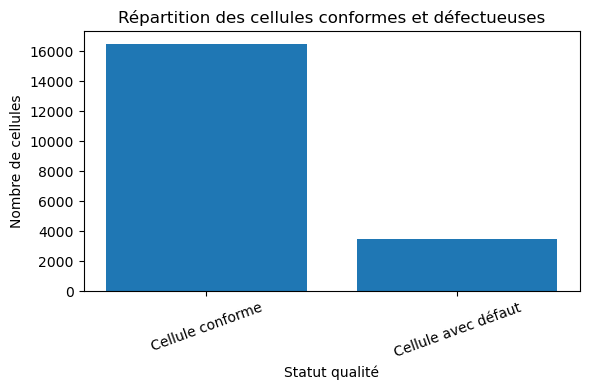

In [82]:
plt.figure(figsize=(6, 4))
plt.bar(defect_distribution["statut"], defect_distribution["total"])
plt.title("Répartition des cellules conformes et défectueuses")
plt.xlabel("Statut qualité")
plt.ylabel("Nombre de cellules")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "repartition_has_defect.png", bbox_inches="tight")
plt.show()

# 18. Analyse des types de défauts

In [83]:
defect_type_distribution = pd.read_sql_query(
    """
    SELECT Defect_Type, COUNT(*) AS total
    FROM battery_qc_clean
    GROUP BY Defect_Type
    ORDER BY total DESC;
    """,
    conn
)

defect_type_distribution

,Defect_Type,total
0,Unknown,16499
1,High Internal Resistance,2837
2,Poor Retention,524
3,Critical Resistance,117
4,Low Capacity,11
5,Severe Capacity Fade,8
6,Short Circuit Risk (Overhang),4


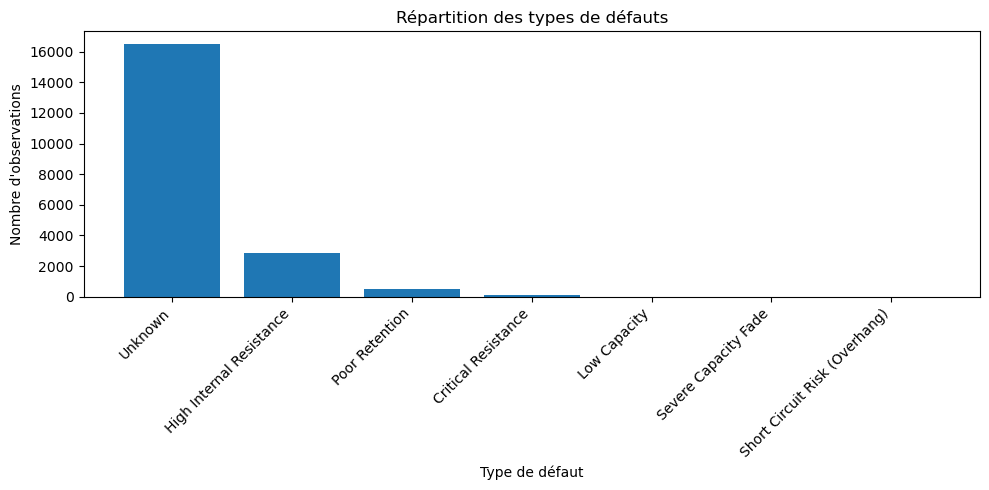

In [84]:
plt.figure(figsize=(10, 5))
plt.bar(defect_type_distribution["Defect_Type"], defect_type_distribution["total"])
plt.title("Répartition des types de défauts")
plt.xlabel("Type de défaut")
plt.ylabel("Nombre d'observations")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "repartition_defect_type.png", bbox_inches="tight")
plt.show()

# 19. Préparation des données pour le machine learning

In [85]:
target_col = "Has_Defect"

columns_to_drop = [
    "Has_Defect",
    "Defect_Type",
    "Inspector_Comment",
    "QC_Grade"
]

id_columns = [col for col in df_clean.columns if "id" in col.lower()]

columns_to_drop = columns_to_drop + id_columns

print("Colonnes supprimées du modèle :")
print(columns_to_drop)

X = df_clean.drop(columns=columns_to_drop)
y = df_clean[target_col]

print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

Colonnes supprimées du modèle :
['Has_Defect', 'Defect_Type', 'Inspector_Comment', 'QC_Grade', 'Cell_ID', 'Batch_ID']
Dimensions de X : (20000, 9)
Dimensions de y : (20000,)


# 20. Identification des variables numériques et catégorielles

In [86]:
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Variables numériques :")
print(numeric_features)

print("\nVariables catégorielles :")
print(categorical_features)

Variables numériques :
['Ambient_Temp_C', 'Anode_Overhang_mm', 'Electrolyte_Volume_ml', 'Internal_Resistance_mOhm', 'Capacity_mAh', 'Retention_50Cycle_Pct']

Variables catégorielles :
['Production_Line', 'Shift', 'Supplier']


# 21. Séparation train/test

In [87]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Taille du jeu d'entraînement :", X_train.shape)
print("Taille du jeu de test :", X_test.shape)

print("\nPourcentage entraînement :", round(len(X_train) / len(X) * 100, 2), "%")
print("Pourcentage test :", round(len(X_test) / len(X) * 100, 2), "%")

Taille du jeu d'entraînement : (16000, 9)
Taille du jeu de test : (4000, 9)

Pourcentage entraînement : 80.0 %
Pourcentage test : 20.0 %


# 22. Prétraitement des variables

In [88]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# 23. Entraînement de plusieurs modèles

In [89]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(random_state=42, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ),
    "KNN": KNeighborsClassifier(n_neighbors=5)
}

results = []
trained_models = {}

for name, model in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    
    accuracy = accuracy_score(y_test, y_pred)
    
    report = classification_report(
        y_test,
        y_pred,
        output_dict=True,
        zero_division=0
    )
    
    results.append({
        "modele": name,
        "accuracy": accuracy,
        "precision_classe_1": report["1"]["precision"],
        "rappel_classe_1": report["1"]["recall"],
        "f1_score_classe_1": report["1"]["f1-score"]
    })
    
    trained_models[name] = pipeline
    
    print("=" * 70)
    print("Modèle :", name)
    print("Accuracy :", round(accuracy, 4))
    print(classification_report(y_test, y_pred, zero_division=0))

Modèle : Logistic Regression
Accuracy : 0.8842
              precision    recall  f1-score   support

           0       0.97      0.88      0.93      3300
           1       0.62      0.89      0.73       700

    accuracy                           0.88      4000
   macro avg       0.80      0.89      0.83      4000
weighted avg       0.91      0.88      0.89      4000

Modèle : Decision Tree
Accuracy : 0.978
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      3300
           1       0.94      0.93      0.94       700

    accuracy                           0.98      4000
   macro avg       0.96      0.96      0.96      4000
weighted avg       0.98      0.98      0.98      4000

Modèle : Random Forest
Accuracy : 0.9842
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      3300
           1       0.98      0.93      0.95       700

    accuracy                           0.98      4000


# 24. Tableau comparatif des modèles

In [90]:
results_df = pd.DataFrame(results).sort_values(
    by=["f1_score_classe_1", "rappel_classe_1", "accuracy"],
    ascending=False
)

results_df

,modele,accuracy,precision_classe_1,rappel_classe_1,f1_score_classe_1
2,Random Forest,0.98425,0.983308,0.925714,0.953642
1,Decision Tree,0.97800,0.942197,0.931429,0.936782
3,KNN,0.93750,0.924528,0.700000,0.796748
0,Logistic Regression,0.88425,0.617443,0.890000,0.729081


In [91]:
results_df.to_csv(OUTPUT_DIR / "comparaison_modeles.csv", index=False)

# 25. Sélection du meilleur modèle

In [92]:
best_model_name = results_df.iloc[0]["modele"]
best_model = trained_models[best_model_name]

print("Meilleur modèle retenu :", best_model_name)
print("Accuracy :", round(results_df.iloc[0]["accuracy"], 4))
print("F1-score classe défaut :", round(results_df.iloc[0]["f1_score_classe_1"], 4))
print("Rappel classe défaut :", round(results_df.iloc[0]["rappel_classe_1"], 4))

Meilleur modèle retenu : Random Forest
Accuracy : 0.9842
F1-score classe défaut : 0.9536
Rappel classe défaut : 0.9257


# 26. Matrice de confusion du meilleur modèle

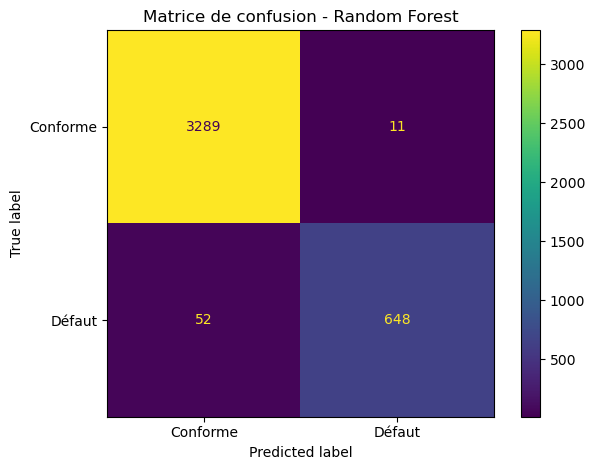

In [93]:
y_pred_best = best_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred_best)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Conforme", "Défaut"]
)

disp.plot()
plt.title(f"Matrice de confusion - {best_model_name}")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "matrice_confusion_best_model.png", bbox_inches="tight")
plt.show()

# 27. Rapport de classification du meilleur modèle

In [94]:
report_best = classification_report(
    y_test,
    y_pred_best,
    target_names=["Conforme", "Défaut"],
    output_dict=True,
    zero_division=0
)

report_best_df = pd.DataFrame(report_best).transpose()

report_best_df

,precision,recall,f1-score,support
Conforme,0.984436,0.996667,0.990513,3300.00000
Défaut,0.983308,0.925714,0.953642,700.00000
accuracy,0.984250,0.984250,0.984250,0.98425
macro avg,0.983872,0.961190,0.972078,4000.00000
weighted avg,0.984238,0.984250,0.984061,4000.00000


In [95]:
report_best_df.to_csv(OUTPUT_DIR / "classification_report_best_model.csv")

# 28. Sauvegarde du meilleur modèle

In [96]:
model_path = MODEL_DIR / "best_battery_defect_model.pkl"

joblib.dump(best_model, model_path)

print("Modèle sauvegardé ici :", model_path)

Modèle sauvegardé ici : models/best_battery_defect_model.pkl


# 29. Comparaison des temps SQL avant optimisation

In [97]:
def measure_query_time(query, conn, repeat=30):
    times = []
    for _ in range(repeat):
        start = time.perf_counter()
        pd.read_sql_query(query, conn)
        end = time.perf_counter()
        times.append((end - start) * 1000)
    return np.mean(times)

On mesure quelques requêtes avant index :

In [98]:
queries_before = {
    "Comptage total": "SELECT COUNT(*) AS total FROM battery_qc_clean;",
    "Filtrage cellules avec défaut": "SELECT * FROM battery_qc_clean WHERE Has_Defect = 1;",
    "Regroupement par type de défaut": """
        SELECT Defect_Type, COUNT(*) AS total
        FROM battery_qc_clean
        GROUP BY Defect_Type;
    """,
    "Regroupement par ligne de production": """
        SELECT Production_Line, COUNT(*) AS total
        FROM battery_qc_clean
        GROUP BY Production_Line;
    """
}

times_before = {}

for name, query in queries_before.items():
    times_before[name] = measure_query_time(query, conn)
    
times_before

{'Comptage total': np.float64(0.39064719264085096),
 'Filtrage cellules avec défaut': np.float64(5.23641526621456),
 'Regroupement par type de défaut': np.float64(2.3326096668218574),
 'Regroupement par ligne de production': np.float64(2.480161093020191)}

# 30. Création des index SQL

In [99]:
conn.execute("CREATE INDEX IF NOT EXISTS idx_has_defect ON battery_qc_clean(Has_Defect);")
conn.execute("CREATE INDEX IF NOT EXISTS idx_defect_type ON battery_qc_clean(Defect_Type);")
conn.execute("CREATE INDEX IF NOT EXISTS idx_production_line ON battery_qc_clean(Production_Line);")
conn.commit()

print("Index créés avec succès.")

Index créés avec succès.


# 31. Comparaison des temps SQL après optimisation

In [100]:
times_after = {}

for name, query in queries_before.items():
    times_after[name] = measure_query_time(query, conn)
    
times_after

{'Comptage total': np.float64(0.06225412944331765),
 'Filtrage cellules avec défaut': np.float64(5.364227729539077),
 'Regroupement par type de défaut': np.float64(0.4793667932972312),
 'Regroupement par ligne de production': np.float64(0.4624832305125892)}

Tableau comparatif :

In [101]:
sql_performance = pd.DataFrame({
    "requete": list(times_before.keys()),
    "temps_avant_index_ms": list(times_before.values()),
    "temps_apres_index_ms": list(times_after.values())
})

sql_performance["gain_ms"] = (
    sql_performance["temps_avant_index_ms"] 
    - sql_performance["temps_apres_index_ms"]
)

sql_performance["gain_pourcentage"] = (
    sql_performance["gain_ms"] 
    / sql_performance["temps_avant_index_ms"] 
    * 100
)

sql_performance

,requete,temps_avant_index_ms,temps_apres_index_ms,gain_ms,gain_pourcentage
0,Comptage total,0.390647,0.062254,0.328393,84.063848
1,Filtrage cellules avec défaut,5.236415,5.364228,-0.127812,-2.440839
2,Regroupement par type de défaut,2.332610,0.479367,1.853243,79.449335
3,Regroupement par ligne de production,2.480161,0.462483,2.017678,81.352694


In [102]:
sql_performance.to_csv(OUTPUT_DIR / "comparaison_temps_sql.csv", index=False)

# 32. Graphique comparaison SQL

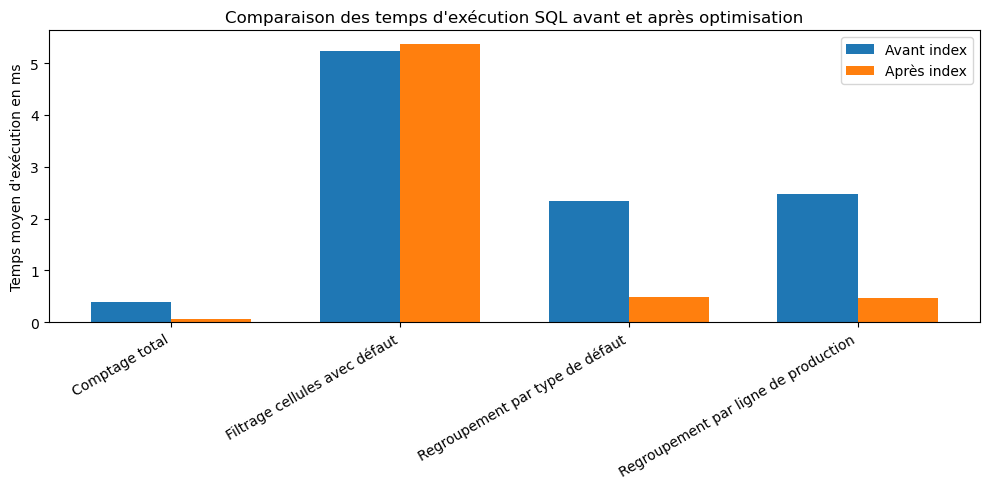

In [103]:
plt.figure(figsize=(10, 5))

x = np.arange(len(sql_performance["requete"]))
width = 0.35

plt.bar(x - width/2, sql_performance["temps_avant_index_ms"], width, label="Avant index")
plt.bar(x + width/2, sql_performance["temps_apres_index_ms"], width, label="Après index")

plt.xticks(x, sql_performance["requete"], rotation=30, ha="right")
plt.ylabel("Temps moyen d'exécution en ms")
plt.title("Comparaison des temps d'exécution SQL avant et après optimisation")
plt.legend()
plt.tight_layout()

plt.savefig(FIGURE_DIR / "comparaison_temps_sql.png", bbox_inches="tight")
plt.show()

# 33. Importance des variables : le meilleur modèle est Random Forest

In [104]:
if best_model_name == "Random Forest":
    model = best_model.named_steps["model"]
    
    feature_names = best_model.named_steps["preprocessor"].get_feature_names_out()
    
    importances = model.feature_importances_
    
    feature_importance_df = pd.DataFrame({
        "variable": feature_names,
        "importance": importances
    }).sort_values(by="importance", ascending=False)
    
    display(feature_importance_df.head(15))
    
    feature_importance_df.to_csv(
        OUTPUT_DIR / "importance_variables_random_forest.csv",
        index=False
    )

,variable,importance
3,num__Internal_Resistance_mOhm,0.494408
1,num__Anode_Overhang_mm,0.127031
4,num__Capacity_mAh,0.103614
5,num__Retention_50Cycle_Pct,0.098039
2,num__Electrolyte_Volume_ml,0.069360
14,cat__Supplier_VoltIndustries,0.044027
0,num__Ambient_Temp_C,0.029062
12,cat__Supplier_ChemCorp,0.015158
13,cat__Supplier_LithioMat,0.009243
6,cat__Production_Line_Line_1,0.001767


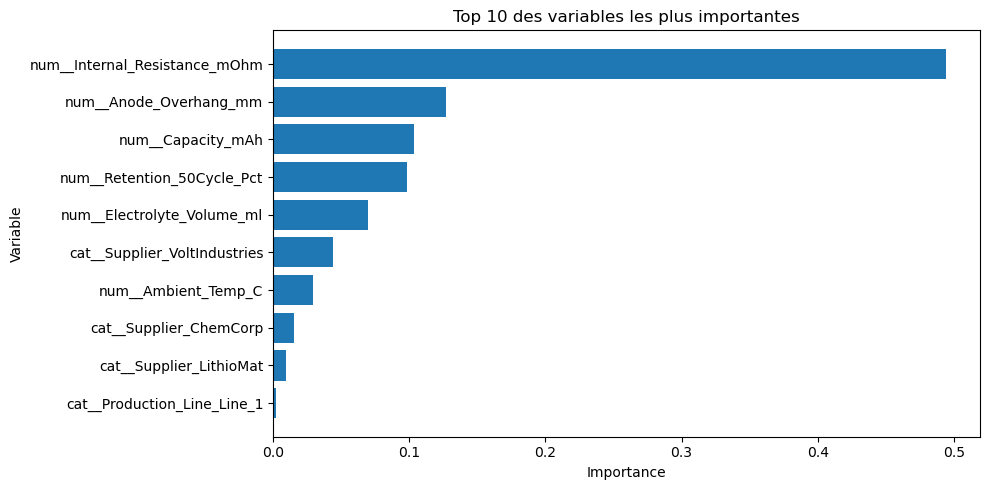

In [105]:
if best_model_name == "Random Forest":
    top_features = feature_importance_df.head(10)
    
    plt.figure(figsize=(10, 5))
    plt.barh(top_features["variable"], top_features["importance"])
    plt.xlabel("Importance")
    plt.ylabel("Variable")
    plt.title("Top 10 des variables les plus importantes")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    
    plt.savefig(FIGURE_DIR / "importance_variables_random_forest.png", bbox_inches="tight")
    plt.show()

# 34. Tableau de suivi des problématiques techniques

In [106]:
problemes = pd.DataFrame({
    "index": [1, 2, 3, 4, 5, 6],
    "date_probleme": [
        "25/08/2026",
        "25/08/2026",
        "25/08/2026",
        "25/08/2026",
        "25/08/2026",
        "25/08/2026"
    ],
    "problematique_technique": [
        "Téléchargement du dataset Kaggle",
        "Importation des données dans SQLite",
        "Présence de valeurs manquantes dans certaines colonnes",
        "Création de la variable cible binaire",
        "Encodage des variables catégorielles",
        "Optimisation des requêtes SQL"
    ],
    "date_resolution": [
        "25/08/2026",
        "25/08/2026",
        "25/08/2026",
        "25/08/2026",
        "25/08/2026",
        "25/08/2026"
    ],
    "solution_apportee": [
        "Utilisation de la librairie kagglehub pour télécharger automatiquement le dataset.",
        "Création d'une base SQLite et insertion du fichier CSV dans la table battery_qc_raw.",
        "Remplacement des valeurs manquantes numériques par la médiane et des valeurs catégorielles par Unknown.",
        "Transformation de la colonne Defect_Type en variable binaire Has_Defect.",
        "Utilisation de OneHotEncoder dans un pipeline scikit-learn.",
        "Création d'index sur les colonnes Has_Defect, Defect_Type et Production_Line."
    ]
})

problemes

,index,date_probleme,problematique_technique,date_resolution,solution_apportee
0,1,25/08/2026,Téléchargement du dataset Kaggle,25/08/2026,Utilisation de la librairie kagglehub pour tél...
1,2,25/08/2026,Importation des données dans SQLite,25/08/2026,Création d'une base SQLite et insertion du fic...
2,3,25/08/2026,Présence de valeurs manquantes dans certaines ...,25/08/2026,Remplacement des valeurs manquantes numériques...
3,4,25/08/2026,Création de la variable cible binaire,25/08/2026,Transformation de la colonne Defect_Type en va...
4,5,25/08/2026,Encodage des variables catégorielles,25/08/2026,Utilisation de OneHotEncoder dans un pipeline ...
5,6,25/08/2026,Optimisation des requêtes SQL,25/08/2026,"Création d'index sur les colonnes Has_Defect, ..."


In [107]:
problemes.to_csv(OUTPUT_DIR / "suivi_problemes_techniques.csv", index=False)

# 35. Vérification finale des fichiers générés

In [108]:
print("Fichiers dans outputs :")
for file in OUTPUT_DIR.iterdir():
    print("-", file.name)

print("\nFichiers dans figures :")
for file in FIGURE_DIR.iterdir():
    print("-", file.name)

print("\nFichiers dans models :")
for file in MODEL_DIR.iterdir():
    print("-", file.name)

Fichiers dans outputs :
- battery_qc.sqlite
- classification_report_best_model.csv
- suivi_problemes_techniques.csv
- importance_variables_random_forest.csv
- comparaison_temps_sql.csv
- comparaison_modeles.csv

Fichiers dans figures :
- repartition_has_defect.png
- comparaison_temps_sql.png
- importance_variables_random_forest.png
- repartition_defect_type.png
- matrice_confusion_best_model.png

Fichiers dans models :
- best_battery_defect_model.pkl


# 36. Fermeture de la connexion SQLite

In [109]:
conn.close()
print("Connexion SQLite fermée.")

Connexion SQLite fermée.


# 37. Tests

In [119]:
features_app = [
    "Production_Line",
    "Shift",
    "Supplier",
    "Ambient_Temp_C",
    "Anode_Overhang_mm",
    "Electrolyte_Volume_ml",
    "Internal_Resistance_mOhm",
    "Capacity_mAh",
    "Retention_50Cycle_Pct"
]

df_test_app = df_clean[features_app].copy()

predictions = best_model.predict(df_test_app)

df_examples = df_clean[features_app].copy()
df_examples["prediction"] = predictions

exemple_predit_conforme = df_examples[df_examples["prediction"] == 0].head(1)
exemple_predit_defaut = df_examples[df_examples["prediction"] == 1].head(1)

print("Exemple prédit conforme :")
display(exemple_predit_conforme)

print("Exemple prédit défaut :")
display(exemple_predit_defaut)

Exemple prédit conforme :


,Production_Line,Shift,Supplier,Ambient_Temp_C,Anode_Overhang_mm,Electrolyte_Volume_ml,Internal_Resistance_mOhm,Capacity_mAh,Retention_50Cycle_Pct,prediction
1,Line_1,Night,ChemCorp,22.38,0.126,14.96,14.7,4989.0,97.35,0


Exemple prédit défaut :


,Production_Line,Shift,Supplier,Ambient_Temp_C,Anode_Overhang_mm,Electrolyte_Volume_ml,Internal_Resistance_mOhm,Capacity_mAh,Retention_50Cycle_Pct,prediction
0,Line_3,Evening,ChemCorp,20.76,0.108,14.81,14.01,4980.0,97.79,1
